In [1]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/250331/C_VRV/structure_feature_detection_evaluation/interaction_distribution")
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
import seaborn as sns
import pandas as pd
from scipy.stats import mannwhitneyu
import itertools
from statsmodels.stats.multitest import multipletests

In [2]:
total = []
with open("total_support.txt","r")as f:
    for line in f:
        total.append(float(line.strip()))
total = np.array(total)

In [3]:
short_ref = []
with open("shor_ref_support.txt","r")as f:
    for line in f:
        short_ref.append(float(line.strip()))
short_ref = np.array(short_ref)

In [4]:
long_ref = []
with open("long_ref_support.txt","r")as f:
    for line in f:
        long_ref.append(float(line.strip()))
long_ref = np.array(long_ref)

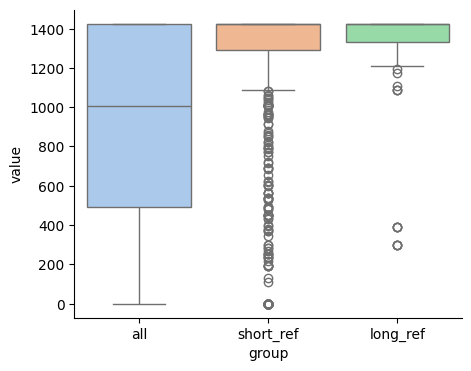

In [5]:
fig, axs = plt.subplots(1, figsize=(5, 4))

all_data = [total,short_ref,long_ref]

labels = ['all','short_ref','long_ref']

df = pd.DataFrame({
    'value': np.concatenate(all_data),
    'group': np.repeat(labels, [len(data) for data in all_data])
})

ax = sns.boxplot(x='group', y='value', data=df, hue='group', legend=False,palette="pastel") #, cut=0 ,showfliers=False

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 显示图形
plt.savefig("filter_compare.pdf", format="pdf", bbox_inches="tight")

In [ ]:
def perform_all_pairwise_comparisons(data_list, names, alpha=0.05):
    combinations = list(itertools.combinations(range(len(data_list)), 2))
    
    results = []
    p_values = []
    
    print("=" * 60)
    print("n:")
    for i, name in enumerate(names):
        print(f"{name}: n = {len(data_list[i])}")
    
    print("=" * 60)
    print("result:")
    print("=" * 60)
    
    for i, j in combinations:
        data_i = data_list[i]
        data_j = data_list[j]
        n_i = len(data_i)
        n_j = len(data_j)
        
        stat, p_val = mannwhitneyu(data_i, data_j, alternative='two-sided')
        
        effect_r = 1 - (2 * stat) / (n_i * n_j)
        
        median_i = np.median(data_i)
        median_j = np.median(data_j)
        mean_i = np.mean(data_i)
        mean_j = np.mean(data_j)
        iqr_i = np.percentile(data_i, 75) - np.percentile(data_i, 25)
        iqr_j = np.percentile(data_j, 75) - np.percentile(data_j, 25)
        
        results.append({
            'Comparison': f'{names[i]} vs {names[j]}',
            'U_Statistic': stat,
            'P_Value': p_val,
            'Effect_Size_r': effect_r,
            'n1': n_i,
            'n2': n_j,
            'Median1': median_i,
            'Median2': median_j,
            'Median_Diff': median_i - median_j,
            'Mean1': mean_i,
            'Mean2': mean_j,
            'IQR1': iqr_i,
            'IQR2': iqr_j
        })
        p_values.append(p_val)
        
        print(f"{names[i]} vs {names[j]}: U = {stat:.0f}, p = {p_val:.3e}, r = {effect_r:.3f}")
        print(f"  n: {names[i]}={n_i}, {names[j]}={n_j}")
        print(f"  median: {names[i]}={median_i:.3f}, {names[j]}={median_j:.3f}")
        print(f"  median_diff: {median_i - median_j:.3f}")
    
    rejected, corrected_pvals, _, _ = multipletests(p_values, alpha=alpha, method='holm')
    
    print("\n" + "=" * 60)
    print("=" * 60)
    
    results_df = pd.DataFrame(results)
    results_df['Adjusted_P_Value'] = corrected_pvals
    results_df['Significant'] = rejected
    results_df['Sig_Marker'] = results_df['Adjusted_P_Value'].apply(
        lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    )
    
    return results_df

alpha = 0.05
results_df = perform_all_pairwise_comparisons(all_data, labels, alpha=alpha)

print("\ntable:")
print("=" * 60)
print(results_df.to_string(index=False))

print("\nsummary:")
print("=" * 60)
sig_comparisons = results_df[results_df['Significant']]
if len(sig_comparisons) > 0:
    for _, row in sig_comparisons.iterrows():
        print(f"{row['Comparison']}: {row['Sig_Marker']} (p_adj = {row['Adjusted_P_Value']:.3e}, r = {row['Effect_Size_r']:.3f})")
else:
    print("n.s.")

print("\n|r|:")
print("=" * 60)
for _, row in results_df.iterrows():
    effect_size = abs(row['Effect_Size_r'])
    print(f"{row['Comparison']}: |r| = {effect_size:.3f}")